<a href="https://colab.research.google.com/github/arunrs2210/smart-traffic-signal-optimization/blob/main/smart_traffic_control_using_RL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# STEP 1: Environment Setup

import numpy as np
import matplotlib.pyplot as plt
import random
import time

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)

print("Smart Traffic Signal RL Project")
print("--------------------------------")
print("NumPy Version:", np.__version__)
print("Environment Setup Successful!")

Smart Traffic Signal RL Project
--------------------------------
NumPy Version: 2.4.6
Environment Setup Successful!


In [2]:
# STEP 2: Four-Way Traffic Intersection Environment

import numpy as np
import random

class TrafficEnvironment:

    def __init__(self):
        self.max_steps = 100
        self.service_rate = 3

        # Vehicle arrival rates
        self.ns_arrival_rate = 2.0
        self.ew_arrival_rate = 1.5

        self.reset()

    def reset(self):

        # Initial vehicle queues
        self.ns_queue = 0
        self.ew_queue = 0

        self.current_step = 0

        self.total_vehicles_served = 0
        self.total_waiting_time = 0

        return self.get_state()

    def get_state(self):

        # Discretize queue lengths into 4 levels
        ns_state = min(self.ns_queue // 3, 3)
        ew_state = min(self.ew_queue // 3, 3)

        return (ns_state, ew_state)

    def step(self, action):

        # Generate random vehicle arrivals
        ns_arrivals = np.random.poisson(
            self.ns_arrival_rate
        )

        ew_arrivals = np.random.poisson(
            self.ew_arrival_rate
        )

        self.ns_queue += ns_arrivals
        self.ew_queue += ew_arrivals

        # Action 0: North-South Green
        # Action 1: East-West Green

        if action == 0:

            vehicles_served = min(
                self.ns_queue,
                self.service_rate
            )

            self.ns_queue -= vehicles_served

        else:

            vehicles_served = min(
                self.ew_queue,
                self.service_rate
            )

            self.ew_queue -= vehicles_served

        # Calculate waiting time approximation
        waiting = self.ns_queue + self.ew_queue

        self.total_waiting_time += waiting
        self.total_vehicles_served += vehicles_served

        # Reward: Lower congestion gives better reward
        reward = -waiting

        self.current_step += 1

        done = self.current_step >= self.max_steps

        next_state = self.get_state()

        info = {
            "NS Queue": self.ns_queue,
            "EW Queue": self.ew_queue,
            "Vehicles Served": vehicles_served,
            "Waiting": waiting
        }

        return next_state, reward, done, info


# Create environment
env = TrafficEnvironment()

print("Traffic Environment Created Successfully!")

print("Initial State:", env.reset())

Traffic Environment Created Successfully!
Initial State: (0, 0)


In [3]:
# Testing the Traffic Environment

state = env.reset()

for step in range(10):

    # Randomly select a traffic signal
    action = random.choice([0, 1])

    next_state, reward, done, info = env.step(action)

    signal = "NORTH-SOUTH GREEN" if action == 0 else "EAST-WEST GREEN"

    print("\nStep:", step + 1)
    print("Signal:", signal)
    print("North-South Queue:", info["NS Queue"])
    print("East-West Queue:", info["EW Queue"])
    print("Vehicles Served:", info["Vehicles Served"])
    print("Reward:", reward)


Step: 1
Signal: NORTH-SOUTH GREEN
North-South Queue: 1
East-West Queue: 0
Vehicles Served: 3
Reward: -1

Step: 2
Signal: NORTH-SOUTH GREEN
North-South Queue: 0
East-West Queue: 3
Vehicles Served: 1
Reward: -3

Step: 3
Signal: EAST-WEST GREEN
North-South Queue: 3
East-West Queue: 0
Vehicles Served: 3
Reward: -3

Step: 4
Signal: NORTH-SOUTH GREEN
North-South Queue: 2
East-West Queue: 1
Vehicles Served: 3
Reward: -3

Step: 5
Signal: NORTH-SOUTH GREEN
North-South Queue: 0
East-West Queue: 2
Vehicles Served: 3
Reward: -2

Step: 6
Signal: NORTH-SOUTH GREEN
North-South Queue: 0
East-West Queue: 3
Vehicles Served: 2
Reward: -3

Step: 7
Signal: NORTH-SOUTH GREEN
North-South Queue: 0
East-West Queue: 3
Vehicles Served: 1
Reward: -3

Step: 8
Signal: NORTH-SOUTH GREEN
North-South Queue: 1
East-West Queue: 5
Vehicles Served: 3
Reward: -6

Step: 9
Signal: EAST-WEST GREEN
North-South Queue: 2
East-West Queue: 4
Vehicles Served: 3
Reward: -6

Step: 10
Signal: NORTH-SOUTH GREEN
North-South Queue: 1
Ea

In [4]:
# STEP 3: Q-Learning Agent

import numpy as np
import random

# Adjust traffic settings for a manageable simulation
env.ns_arrival_rate = 1.2
env.ew_arrival_rate = 1.0
env.service_rate = 3

# Q-Learning parameters
learning_rate = 0.1
discount_factor = 0.95

epsilon = 1.0
epsilon_decay = 0.995
min_epsilon = 0.01

# Q-table: 4 x 4 states, 2 actions
q_table = np.zeros((4, 4, 2))

print("Q-Learning Agent Created!")
print("Q-Table Shape:", q_table.shape)
print("Learning Rate:", learning_rate)
print("Discount Factor:", discount_factor)

Q-Learning Agent Created!
Q-Table Shape: (4, 4, 2)
Learning Rate: 0.1
Discount Factor: 0.95


In [5]:
# Action Selection: Epsilon-Greedy Strategy

def choose_action(state, epsilon):

    # Exploration: Choose a random action
    if random.random() < epsilon:
        return random.choice([0, 1])

    # Exploitation: Choose the best learned action
    return np.argmax(q_table[state[0], state[1]])


print("Action Selection Function Created!")

Action Selection Function Created!


In [6]:
# Q-Learning Update Rule

def update_q_table(state, action, reward, next_state):

    old_value = q_table[state[0], state[1], action]

    next_max = np.max(
        q_table[next_state[0], next_state[1]]
    )

    new_value = old_value + learning_rate * (
        reward + discount_factor * next_max - old_value
    )

    q_table[state[0], state[1], action] = new_value


print("Q-Table Update Function Created!")

Q-Table Update Function Created!


In [7]:
# Testing the Q-Learning Agent

state = env.reset()

action = choose_action(state, epsilon=0)

print("Current State:", state)

if action == 0:
    print("Selected Action: NORTH-SOUTH GREEN")
else:
    print("Selected Action: EAST-WEST GREEN")

next_state, reward, done, info = env.step(action)

update_q_table(state, action, reward, next_state)

print("Reward:", reward)
print("Next State:", next_state)
print("Q-Table Updated Successfully!")

Current State: (0, 0)
Selected Action: NORTH-SOUTH GREEN
Reward: -3
Next State: (1, 0)
Q-Table Updated Successfully!


In [8]:
# STEP 4: Train the Q-Learning Agent

episodes = 500
max_steps = 100

episode_rewards = []
episode_waiting_times = []
epsilon_values = []

epsilon = 1.0

for episode in range(episodes):

    state = env.reset()

    total_reward = 0
    total_waiting = 0

    for step in range(max_steps):

        # Select traffic signal using epsilon-greedy
        action = choose_action(state, epsilon)

        # Execute action in traffic environment
        next_state, reward, done, info = env.step(action)

        # Update Q-table
        update_q_table(
            state,
            action,
            reward,
            next_state
        )

        total_reward += reward
        total_waiting += info["Waiting"]

        state = next_state

        if done:
            break

    # Store episode results
    episode_rewards.append(total_reward)
    episode_waiting_times.append(total_waiting)
    epsilon_values.append(epsilon)

    # Reduce exploration gradually
    epsilon = max(min_epsilon, epsilon * epsilon_decay)

    if (episode + 1) % 50 == 0:
        print(
            f"Episode: {episode + 1}/{episodes} | "
            f"Reward: {total_reward} | "
            f"Epsilon: {epsilon:.3f}"
        )

print("\nTraining Completed Successfully!")

Episode: 50/500 | Reward: -679 | Epsilon: 0.778
Episode: 100/500 | Reward: -372 | Epsilon: 0.606
Episode: 150/500 | Reward: -301 | Epsilon: 0.471
Episode: 200/500 | Reward: -452 | Epsilon: 0.367
Episode: 250/500 | Reward: -359 | Epsilon: 0.286
Episode: 300/500 | Reward: -309 | Epsilon: 0.222
Episode: 350/500 | Reward: -282 | Epsilon: 0.173
Episode: 400/500 | Reward: -249 | Epsilon: 0.135
Episode: 450/500 | Reward: -596 | Epsilon: 0.105
Episode: 500/500 | Reward: -319 | Epsilon: 0.082

Training Completed Successfully!


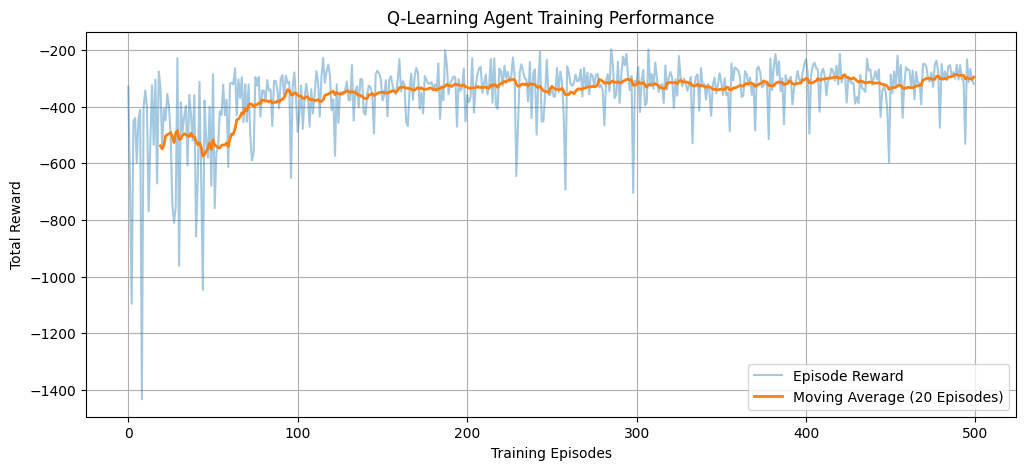

In [9]:
# STEP 4.2: Training Performance Visualization

plt.figure(figsize=(12, 5))

plt.plot(
    episode_rewards,
    alpha=0.4,
    label="Episode Reward"
)

# Calculate moving average
window = 20

moving_average = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.plot(
    range(window - 1, episodes),
    moving_average,
    linewidth=2,
    label="Moving Average (20 Episodes)"
)

plt.title("Q-Learning Agent Training Performance")
plt.xlabel("Training Episodes")
plt.ylabel("Total Reward")
plt.legend()
plt.grid(True)

plt.savefig(
    "training_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# STEP 4.3: Display Learned Q-Table

print("Final Q-Table:\n")

for ns in range(4):
    for ew in range(4):

        values = q_table[ns, ew]

        best_action = np.argmax(values)

        signal = (
            "NORTH-SOUTH GREEN"
            if best_action == 0
            else "EAST-WEST GREEN"
        )

        print(
            f"NS State: {ns} | EW State: {ew} | "
            f"Q Values: {values} | Best Action: {signal}"
        )

print("\nAgent Learning Completed!")

Final Q-Table:

NS State: 0 | EW State: 0 | Q Values: [-57.7854666  -57.83974382] | Best Action: NORTH-SOUTH GREEN
NS State: 0 | EW State: 1 | Q Values: [-61.31750689 -57.97584683] | Best Action: EAST-WEST GREEN
NS State: 0 | EW State: 2 | Q Values: [-72.20163027 -61.91189911] | Best Action: EAST-WEST GREEN
NS State: 0 | EW State: 3 | Q Values: [-77.19265354 -75.40779668] | Best Action: EAST-WEST GREEN
NS State: 1 | EW State: 0 | Q Values: [-59.02452698 -63.79054888] | Best Action: NORTH-SOUTH GREEN
NS State: 1 | EW State: 1 | Q Values: [-70.80190068 -63.15798867] | Best Action: EAST-WEST GREEN
NS State: 1 | EW State: 2 | Q Values: [-74.32893    -76.02658753] | Best Action: NORTH-SOUTH GREEN
NS State: 1 | EW State: 3 | Q Values: [-62.02354858 -62.22527467] | Best Action: NORTH-SOUTH GREEN
NS State: 2 | EW State: 0 | Q Values: [-67.2863901  -73.74654624] | Best Action: NORTH-SOUTH GREEN
NS State: 2 | EW State: 1 | Q Values: [-75.05786723 -76.41502836] | Best Action: NORTH-SOUTH GREEN
NS

In [11]:
# STEP 5: Evaluate Traffic Signal Controllers

def evaluate_controller(controller, episodes=100):

    waiting_results = []
    served_results = []

    for episode in range(episodes):

        # Use repeatable traffic arrivals
        np.random.seed(1000 + episode)
        random.seed(1000 + episode)

        state = env.reset()

        total_waiting = 0
        total_served = 0

        for step in range(100):

            if controller == "Random":
                action = random.choice([0, 1])

            else:
                action = np.argmax(
                    q_table[state[0], state[1]]
                )

            next_state, reward, done, info = env.step(action)

            total_waiting += info["Waiting"]
            total_served += info["Vehicles Served"]

            state = next_state

            if done:
                break

        waiting_results.append(total_waiting)
        served_results.append(total_served)

    return np.mean(waiting_results), np.mean(served_results)


# Evaluate both controllers
random_waiting, random_served = evaluate_controller("Random")

rl_waiting, rl_served = evaluate_controller("RL")

print("TRAFFIC CONTROL PERFORMANCE")
print("--------------------------------")

print("\nRandom Signal Control:")
print("Average Waiting:", round(random_waiting, 2))
print("Average Vehicles Served:", round(random_served, 2))

print("\nQ-Learning Control:")
print("Average Waiting:", round(rl_waiting, 2))
print("Average Vehicles Served:", round(rl_served, 2))

TRAFFIC CONTROL PERFORMANCE
--------------------------------

Random Signal Control:
Average Waiting: 603.95
Average Vehicles Served: 212.84

Q-Learning Control:
Average Waiting: 295.67
Average Vehicles Served: 216.33


In [12]:
# Calculate improvement

if random_waiting > 0:
    improvement = (
        (random_waiting - rl_waiting) / random_waiting
    ) * 100
else:
    improvement = 0

print("PERFORMANCE COMPARISON")
print("--------------------------------")

print("Random Waiting:", round(random_waiting, 2))
print("RL Waiting:", round(rl_waiting, 2))

print("Waiting Time Improvement:",
      round(improvement, 2), "%")

if improvement > 0:
    print("\nQ-Learning reduced traffic waiting!")
else:
    print("\nQ-Learning did not outperform random control.")
    print("Further training or parameter tuning may be needed.")

PERFORMANCE COMPARISON
--------------------------------
Random Waiting: 603.95
RL Waiting: 295.67
Waiting Time Improvement: 51.04 %

Q-Learning reduced traffic waiting!


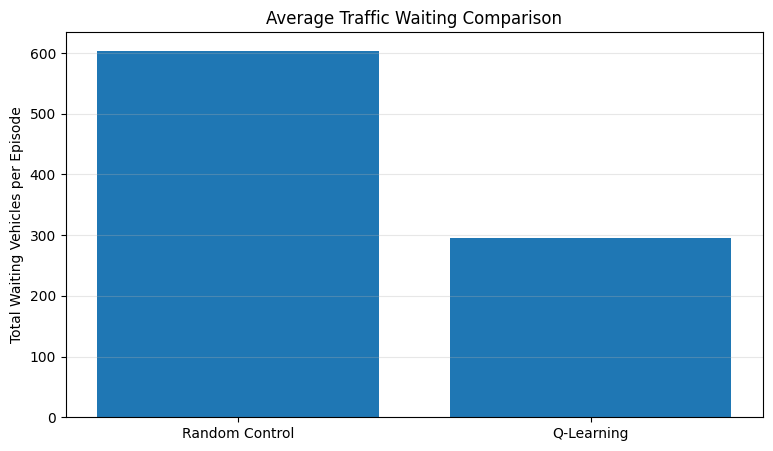

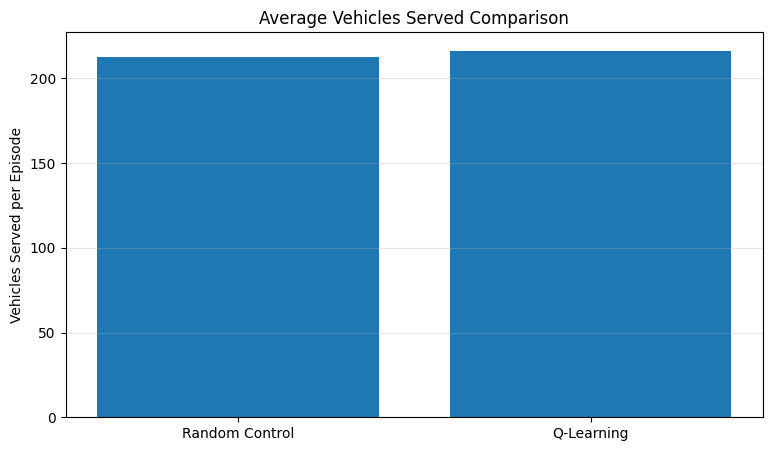

Comparison graphs saved successfully!


In [13]:
# Performance Comparison Graph

methods = ["Random Control", "Q-Learning"]
waiting_values = [random_waiting, rl_waiting]
served_values = [random_served, rl_served]

plt.figure(figsize=(9, 5))

plt.bar(methods, waiting_values)

plt.title("Average Traffic Waiting Comparison")
plt.ylabel("Total Waiting Vehicles per Episode")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "traffic_waiting_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(9, 5))

plt.bar(methods, served_values)

plt.title("Average Vehicles Served Comparison")
plt.ylabel("Vehicles Served per Episode")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "vehicles_served_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison graphs saved successfully!")

In [16]:
# ============================================================
# ADVANCED SMART TRAFFIC CONTROL DASHBOARD
# Reinforcement Learning - Q-Learning
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Reset traffic simulation
state = env.reset()

# Reset dashboard counters
total_served = 0
total_reward = 0
waiting_history = []

# ============================================================
# 1. DASHBOARD DESIGN
# ============================================================

fig = plt.figure(figsize=(15, 9), facecolor="#101827")

fig.suptitle(
    "INTELLIGENT SMART TRAFFIC CONTROL SYSTEM",
    fontsize=19,
    fontweight="bold",
    color="white",
    y=0.97
)

# Traffic intersection panel
ax = fig.add_axes([0.04, 0.12, 0.57, 0.77])

ax.set_facecolor("#172338")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect("equal")
ax.axis("off")

# ============================================================
# 2. DRAW ROAD INTERSECTION
# ============================================================

# Vertical road
ax.add_patch(
    patches.Rectangle(
        (39, 0), 22, 100,
        color="#303846"
    )
)

# Horizontal road
ax.add_patch(
    patches.Rectangle(
        (0, 39), 100, 22,
        color="#303846"
    )
)

# Road markings
for y in range(0, 100, 10):

    ax.plot(
        [50, 50],
        [y, y + 5],
        color="white",
        alpha=0.45,
        linewidth=2
    )

for x in range(0, 100, 10):

    ax.plot(
        [x, x + 5],
        [50, 50],
        color="white",
        alpha=0.45,
        linewidth=2
    )

# Direction labels
ax.text(
    50, 94, "NORTH",
    color="white",
    ha="center",
    fontsize=11,
    weight="bold"
)

ax.text(
    50, 5, "SOUTH",
    color="white",
    ha="center",
    fontsize=11,
    weight="bold"
)

ax.text(
    5, 50, "WEST",
    color="white",
    ha="center",
    fontsize=11,
    weight="bold"
)

ax.text(
    95, 50, "EAST",
    color="white",
    ha="center",
    fontsize=11,
    weight="bold"
)

# ============================================================
# 3. TRAFFIC SIGNAL HOUSINGS
# ============================================================

ns_box = patches.FancyBboxPatch(
    (19, 72), 13, 17,
    boxstyle="round,pad=0.5",
    facecolor="#111827"
)

ew_box = patches.FancyBboxPatch(
    (68, 72), 13, 17,
    boxstyle="round,pad=0.5",
    facecolor="#111827"
)

ax.add_patch(ns_box)
ax.add_patch(ew_box)

# Signal lights
ns_red = patches.Circle(
    (25.5, 84), 2.5,
    color="#ef4444"
)

ns_green = patches.Circle(
    (25.5, 77), 2.5,
    color="#064e3b"
)

ew_red = patches.Circle(
    (74.5, 84), 2.5,
    color="#7f1d1d"
)

ew_green = patches.Circle(
    (74.5, 77), 2.5,
    color="#22c55e"
)

for light in [
    ns_red,
    ns_green,
    ew_red,
    ew_green
]:

    ax.add_patch(light)

# ============================================================
# 4. CREATE VEHICLES - CORRECTED
# ============================================================

ns_cars = []
ew_cars = []

for i in range(12):

    # North-South vehicles
    car1 = patches.Rectangle(
        (43, 0),
        5, 7,
        facecolor="#38bdf8",
        edgecolor="white",
        linewidth=1
    )

    # East-West vehicles
    car2 = patches.Rectangle(
        (0, 43),
        7, 5,
        facecolor="#fbbf24",
        edgecolor="white",
        linewidth=1
    )

    ax.add_patch(car1)
    ax.add_patch(car2)

    ns_cars.append(car1)
    ew_cars.append(car2)

# ============================================================
# 5. LIVE SYSTEM MONITOR PANEL
# ============================================================

panel = fig.add_axes([0.65, 0.12, 0.31, 0.77])

panel.set_facecolor("#172338")
panel.axis("off")

panel.text(
    0.05, 0.95,
    "LIVE SYSTEM MONITOR",
    color="white",
    fontsize=15,
    weight="bold"
)

signal_status = panel.text(
    0.05, 0.84,
    "",
    color="#22c55e",
    fontsize=13,
    weight="bold"
)

queue_status = panel.text(
    0.05, 0.68,
    "",
    color="white",
    fontsize=12,
    linespacing=2
)

performance_status = panel.text(
    0.05, 0.48,
    "",
    color="#38bdf8",
    fontsize=12,
    linespacing=2
)

agent_status = panel.text(
    0.05, 0.25,
    "",
    color="#fbbf24",
    fontsize=12,
    linespacing=2
)

panel.text(
    0.05, 0.06,
    "RL ENGINE: Q-LEARNING ACTIVE",
    color="#22c55e",
    fontsize=10,
    weight="bold"
)

# ============================================================
# 6. ANIMATION FUNCTION
# ============================================================

def update(frame):

    global state
    global total_served
    global total_reward

    # Agent chooses best learned action
    action = np.argmax(
        q_table[state[0], state[1]]
    )

    # Execute traffic signal action
    next_state, reward, done, info = env.step(action)

    state = next_state

    # Update counters
    total_served += info["Vehicles Served"]
    total_reward += reward

    ns = info["NS Queue"]
    ew = info["EW Queue"]

    waiting = ns + ew

    waiting_history.append(waiting)

    # ========================================================
    # UPDATE TRAFFIC LIGHTS
    # ========================================================

    if action == 0:

        ns_red.set_color("#7f1d1d")
        ns_green.set_color("#22c55e")

        ew_red.set_color("#ef4444")
        ew_green.set_color("#064e3b")

        current_signal = "NORTH-SOUTH GREEN"

    else:

        ns_red.set_color("#ef4444")
        ns_green.set_color("#064e3b")

        ew_red.set_color("#7f1d1d")
        ew_green.set_color("#22c55e")

        current_signal = "EAST-WEST GREEN"

    # ========================================================
    # UPDATE NORTH-SOUTH VEHICLES
    # ========================================================

    for i, car in enumerate(ns_cars):

        if i < min(ns, 12):

            x = 43
            y = 8 + i * 5

            if action == 0:

                y += (frame % 4) * 0.4

            car.set_visible(True)

            # Rectangle supports set_xy()
            car.set_xy((x, y))

        else:

            car.set_visible(False)

    # ========================================================
    # UPDATE EAST-WEST VEHICLES
    # ========================================================

    for i, car in enumerate(ew_cars):

        if i < min(ew, 12):

            x = 8 + i * 5
            y = 43

            if action == 1:

                x += (frame % 4) * 0.4

            car.set_visible(True)

            # Rectangle supports set_xy()
            car.set_xy((x, y))

        else:

            car.set_visible(False)

    # ========================================================
    # UPDATE LIVE STATISTICS
    # ========================================================

    signal_status.set_text(
        "ACTIVE SIGNAL\n\n" + current_signal
    )

    queue_status.set_text(
        f"NORTH-SOUTH QUEUE : {ns}\n\n"
        f"EAST-WEST QUEUE  : {ew}\n\n"
        f"TOTAL CONGESTION : {waiting}"
    )

    performance_status.set_text(
        f"VEHICLES SERVED : {total_served}\n\n"
        f"CURRENT REWARD  : {reward}\n\n"
        f"TOTAL REWARD    : {total_reward}"
    )

    agent_status.set_text(
        "AI DECISION ENGINE\n\n"
        f"STATE  : {state}\n"
        f"ACTION : {action}\n"
        f"STEP   : {frame + 1}"
    )

    return (
        ns_red,
        ns_green,
        ew_red,
        ew_green,
        signal_status,
        queue_status,
        performance_status,
        agent_status,
        *ns_cars,
        *ew_cars
    )

# ============================================================
# 7. START ANIMATION
# ============================================================

animation = FuncAnimation(
    fig,
    update,
    frames=60,
    interval=500,
    repeat=False,
    blit=False,
    cache_frame_data=False
)

plt.close(fig)

display(
    HTML(animation.to_jshtml())
)

print("SMART TRAFFIC DASHBOARD INITIALIZED!")

SMART TRAFFIC DASHBOARD INITIALIZED!


In [17]:
# Export Dashboard Animation

animation.save(
    "Advanced_Smart_Traffic_Dashboard.gif",
    writer="pillow",
    fps=2
)

print("Dashboard GIF Exported Successfully!")

Dashboard GIF Exported Successfully!


In [18]:
# STEP 7: FINAL PERFORMANCE ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Create output folder
os.makedirs("Smart_Traffic_Project_Results", exist_ok=True)

# Performance metrics
metrics = {
    "Metric": [
        "Average Waiting Vehicles",
        "Average Vehicles Served",
        "Waiting Reduction (%)"
    ],

    "Random Control": [
        random_waiting,
        random_served,
        0
    ],

    "Q-Learning": [
        rl_waiting,
        rl_served,
        ((random_waiting - rl_waiting) /
         random_waiting) * 100 if random_waiting > 0 else 0
    ]
}

results_df = pd.DataFrame(metrics)

print("FINAL PERFORMANCE ANALYSIS")
print("============================")

display(results_df.round(2))

# Save results
results_df.to_csv(
    "Smart_Traffic_Project_Results/performance_results.csv",
    index=False
)

print("Performance results saved successfully!")

FINAL PERFORMANCE ANALYSIS


,Metric,Random Control,Q-Learning
0,Average Waiting Vehicles,603.95,295.67
1,Average Vehicles Served,212.84,216.33
2,Waiting Reduction (%),0.00,51.04


Performance results saved successfully!


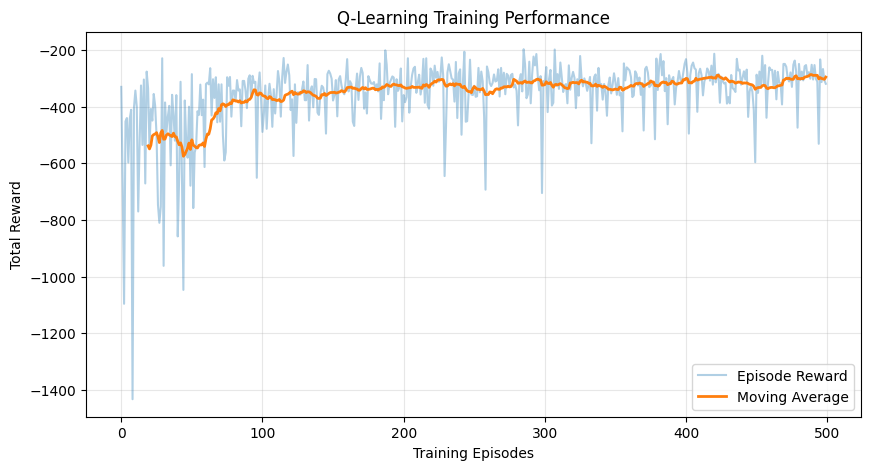

In [19]:
# Training Performance Graph

plt.figure(figsize=(10, 5))

plt.plot(
    episode_rewards,
    alpha=0.35,
    label="Episode Reward"
)

window = 20

moving_average = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.plot(
    range(window - 1, len(episode_rewards)),
    moving_average,
    linewidth=2,
    label="Moving Average"
)

plt.title("Q-Learning Training Performance")
plt.xlabel("Training Episodes")
plt.ylabel("Total Reward")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "Smart_Traffic_Project_Results/training_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Save trained Q-table

np.save(
    "Smart_Traffic_Project_Results/trained_q_table.npy",
    q_table
)

print("Trained Q-table saved successfully!")

Trained Q-table saved successfully!


In [21]:
# Package project results

import shutil

shutil.make_archive(
    "Smart_Traffic_Final_Results",
    "zip",
    "Smart_Traffic_Project_Results"
)

print("Project results ZIP created successfully!")

Project results ZIP created successfully!


In [22]:
# STEP 8: FINAL PROJECT DEMONSTRATION

import numpy as np
import pandas as pd

# Reset simulation
state = env.reset()

demo_results = []

total_vehicles_served = 0
total_waiting = 0
total_reward_demo = 0

print("=" * 55)
print(" INTELLIGENT SMART TRAFFIC SIGNAL OPTIMIZATION")
print("        REINFORCEMENT LEARNING DEMO")
print("=" * 55)

# Run 30 simulation steps
for step in range(30):

    # Select best action learned by Q-Learning
    action = np.argmax(
        q_table[state[0], state[1]]
    )

    # Execute traffic signal
    next_state, reward, done, info = env.step(action)

    signal = (
        "NORTH-SOUTH GREEN"
        if action == 0
        else "EAST-WEST GREEN"
    )

    total_vehicles_served += info["Vehicles Served"]
    total_waiting += info["Waiting"]
    total_reward_demo += reward

    demo_results.append({
        "Step": step + 1,
        "Signal": signal,
        "NS Queue": info["NS Queue"],
        "EW Queue": info["EW Queue"],
        "Vehicles Served": info["Vehicles Served"],
        "Reward": reward
    })

    state = next_state

# Display results
demo_df = pd.DataFrame(demo_results)

display(demo_df)

print("\nFINAL DEMONSTRATION SUMMARY")
print("-" * 40)

print("Simulation Steps:", 30)
print("Vehicles Served:", total_vehicles_served)
print("Total Waiting:", total_waiting)
print("Total Reward:", total_reward_demo)

print("\nQ-LEARNING AGENT EXECUTION SUCCESSFUL!")

 INTELLIGENT SMART TRAFFIC SIGNAL OPTIMIZATION
        REINFORCEMENT LEARNING DEMO


,Step,Signal,NS Queue,EW Queue,Vehicles Served,Reward
0,1,NORTH-SOUTH GREEN,0,0,0,0
1,2,NORTH-SOUTH GREEN,0,0,1,0
2,3,NORTH-SOUTH GREEN,0,3,0,-3
3,4,EAST-WEST GREEN,1,3,3,-4
4,5,EAST-WEST GREEN,1,0,3,-1
5,6,NORTH-SOUTH GREEN,0,1,2,-1
6,7,NORTH-SOUTH GREEN,0,2,0,-2
7,8,NORTH-SOUTH GREEN,0,2,0,-2
8,9,NORTH-SOUTH GREEN,0,3,1,-3
9,10,EAST-WEST GREEN,5,2,3,-7



FINAL DEMONSTRATION SUMMARY
----------------------------------------
Simulation Steps: 30
Vehicles Served: 44
Total Waiting: 75
Total Reward: -75

Q-LEARNING AGENT EXECUTION SUCCESSFUL!


In [23]:
demo_df.to_csv(
    "Smart_Traffic_Demo_Results.csv",
    index=False
)

print("Demonstration results exported successfully!")

Demonstration results exported successfully!


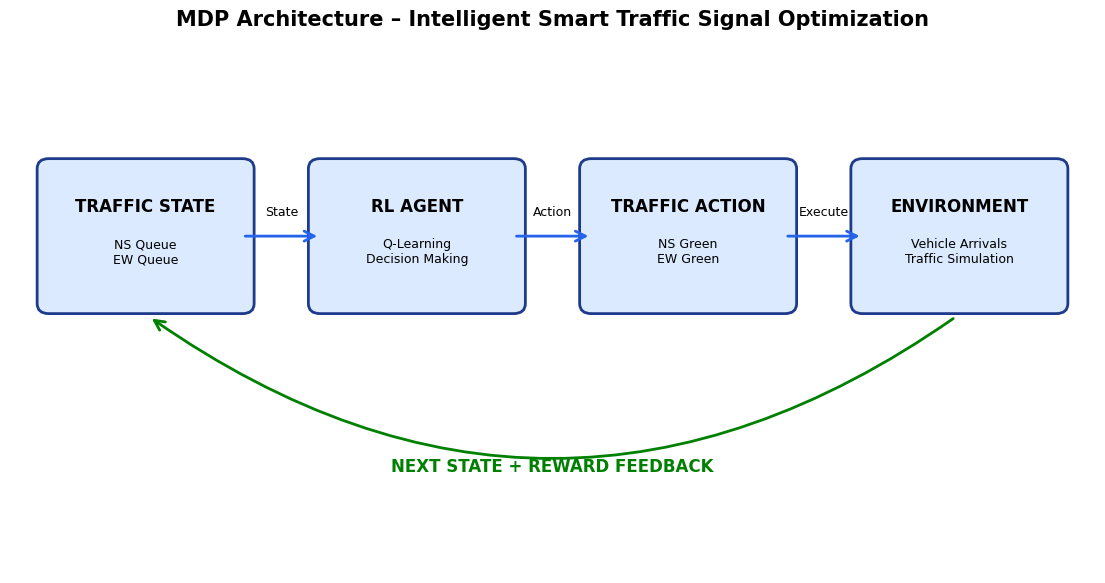

MDP Architecture Diagram Generated!


In [24]:
# TASK 3: MDP ARCHITECTURE DIAGRAM

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(14, 7))

ax.set_xlim(0, 14)
ax.set_ylim(0, 8)
ax.axis("off")

fig.patch.set_facecolor("white")

def draw_box(x, y, width, height, title, description):

    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.15",
        linewidth=2,
        edgecolor="#1e3a8a",
        facecolor="#dbeafe"
    )

    ax.add_patch(box)

    ax.text(
        x + width/2,
        y + height*0.68,
        title,
        ha="center",
        fontsize=12,
        weight="bold"
    )

    ax.text(
        x + width/2,
        y + height*0.30,
        description,
        ha="center",
        fontsize=9
    )

draw_box(0.5, 4, 2.5, 2, "TRAFFIC STATE",
         "NS Queue\nEW Queue")

draw_box(4, 4, 2.5, 2, "RL AGENT",
         "Q-Learning\nDecision Making")

draw_box(7.5, 4, 2.5, 2, "TRAFFIC ACTION",
         "NS Green\nEW Green")

draw_box(11, 4, 2.5, 2, "ENVIRONMENT",
         "Vehicle Arrivals\nTraffic Simulation")

# Arrows
def arrow(x1, y1, x2, y2, label):

    ax.add_patch(
        FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle="->",
            mutation_scale=18,
            linewidth=2,
            color="#2563eb"
        )
    )

    ax.text(
        (x1+x2)/2,
        (y1+y2)/2 + 0.3,
        label,
        ha="center",
        fontsize=9
    )

arrow(3, 5, 4, 5, "State")
arrow(6.5, 5, 7.5, 5, "Action")
arrow(10, 5, 11, 5, "Execute")

# Feedback loop
ax.add_patch(
    FancyArrowPatch(
        (12.2, 3.8),
        (1.8, 3.8),
        connectionstyle="arc3,rad=-0.35",
        arrowstyle="->",
        mutation_scale=18,
        linewidth=2,
        color="green"
    )
)

ax.text(
    7, 1.5,
    "NEXT STATE + REWARD FEEDBACK",
    ha="center",
    fontsize=12,
    color="green",
    weight="bold"
)

plt.title(
    "MDP Architecture – Intelligent Smart Traffic Signal Optimization",
    fontsize=15,
    weight="bold"
)

plt.savefig(
    "MDP_Architecture.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("MDP Architecture Diagram Generated!")

In [26]:
import numpy as np
import pandas as pd
import random

# Find the trained Q-table automatically
possible_names = ["Q_table", "q_table", "Q", "qtable"]

trained_Q = None

for name in possible_names:
    if name in globals():
        candidate = globals()[name]
        if isinstance(candidate, np.ndarray) and candidate.shape == (4, 4, 2):
            trained_Q = candidate
            print("Trained Q-table found:", name)
            break

# Stop if the Q-table cannot be found
if trained_Q is None:
    raise NameError(
        "Trained Q-table not found. Please run your Q-Learning training cell again."
    )

# Initialize traffic queues
ns_queue = 8
ew_queue = 5

arrival_ns = 1.2
arrival_ew = 1.0
service_rate = 3

transition_data = []

for step in range(10):

    # Current state
    state = (
        min(ns_queue // 3, 3),
        min(ew_queue // 3, 3)
    )

    # Select action using trained Q-table
    action = np.argmax(trained_Q[state[0], state[1]])

    # Random vehicle arrivals
    ns_arrivals = np.random.poisson(arrival_ns)
    ew_arrivals = np.random.poisson(arrival_ew)

    ns_queue += ns_arrivals
    ew_queue += ew_arrivals

    # Apply traffic signal
    if action == 0:
        ns_queue = max(0, ns_queue - service_rate)
        action_name = "North-South Green"
    else:
        ew_queue = max(0, ew_queue - service_rate)
        action_name = "East-West Green"

    # Calculate reward
    reward = -(ns_queue + ew_queue)

    # Next state
    next_state = (
        min(ns_queue // 3, 3),
        min(ew_queue // 3, 3)
    )

    transition_data.append({
        "Step": step + 1,
        "Current State": str(state),
        "Action": action_name,
        "Next State": str(next_state),
        "Reward": reward,
        "NS Queue": ns_queue,
        "EW Queue": ew_queue
    })

# Display results
transition_df = pd.DataFrame(transition_data)
display(transition_df)

# Export CSV
transition_df.to_csv("MDP_State_Transitions.csv", index=False)

print("MDP state transition demonstration completed!")

Trained Q-table found: q_table


,Step,Current State,Action,Next State,Reward,NS Queue,EW Queue
0,1,"(2, 1)",North-South Green,"(2, 2)",-12,6,6
1,2,"(2, 2)",North-South Green,"(1, 2)",-13,5,8
2,3,"(1, 2)",North-South Green,"(0, 2)",-10,2,8
3,4,"(0, 2)",East-West Green,"(1, 2)",-10,4,6
4,5,"(1, 2)",North-South Green,"(0, 2)",-9,1,8
5,6,"(0, 2)",East-West Green,"(1, 2)",-10,3,7
6,7,"(1, 2)",North-South Green,"(0, 2)",-8,1,7
7,8,"(0, 2)",East-West Green,"(0, 1)",-7,2,5
8,9,"(0, 1)",East-West Green,"(1, 1)",-7,3,4
9,10,"(1, 1)",East-West Green,"(1, 1)",-7,4,3


MDP state transition demonstration completed!


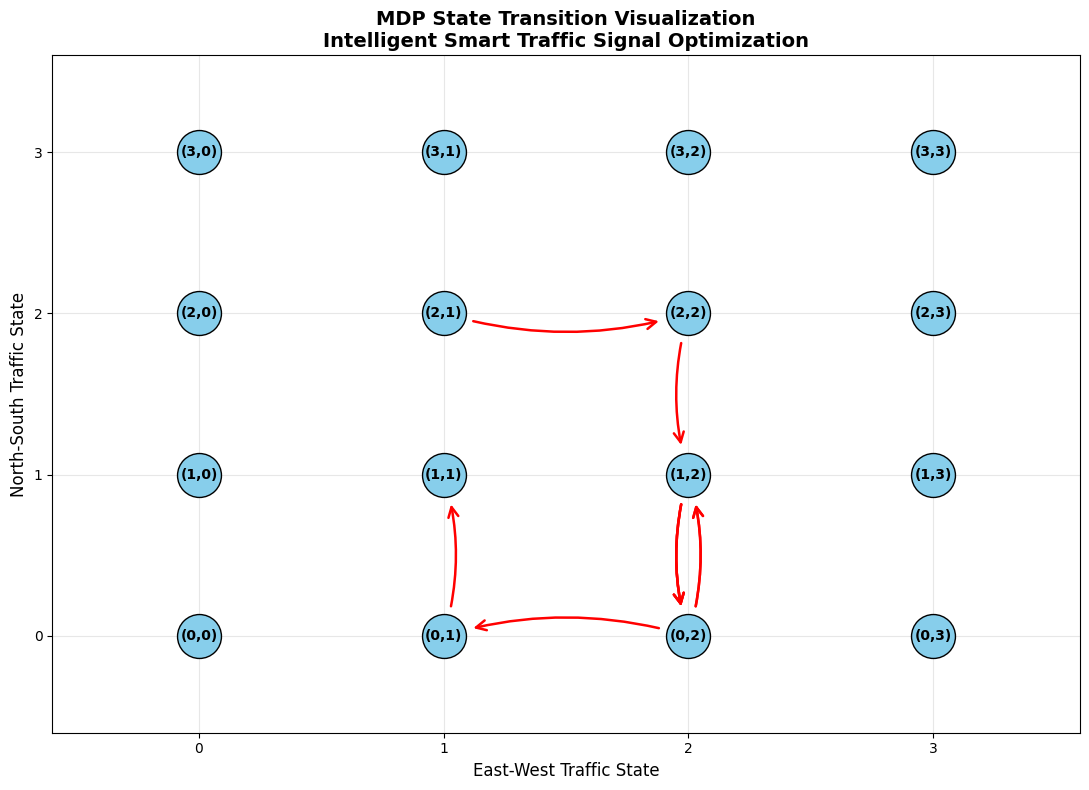

MDP State Transition Graph generated successfully!


In [27]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# Check whether Step 4 results exist
if "transition_df" not in globals():
    raise NameError("Please run Step 4 first to generate transition_df.")

fig, ax = plt.subplots(figsize=(11, 8))

# Plot state positions: x = EW state, y = NS state
for ns in range(4):
    for ew in range(4):
        ax.scatter(ew, ns, s=1000, color="skyblue",
                   edgecolors="black", zorder=3)
        ax.text(ew, ns, f"({ns},{ew})",
                ha="center", va="center",
                fontsize=10, fontweight="bold", zorder=4)

# Draw transitions observed in Step 4
for _, row in transition_df.iterrows():

    current = eval(row["Current State"])
    next_state = eval(row["Next State"])

    start = (current[1], current[0])
    end = (next_state[1], next_state[0])

    # Draw arrow
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="->",
        mutation_scale=18,
        color="red",
        linewidth=1.8,
        connectionstyle="arc3,rad=0.15",
        shrinkA=22,
        shrinkB=22,
        zorder=2
    )

    ax.add_patch(arrow)

ax.set_xlim(-0.6, 3.6)
ax.set_ylim(-0.6, 3.6)

ax.set_xticks(range(4))
ax.set_yticks(range(4))

ax.set_xlabel("East-West Traffic State", fontsize=12)
ax.set_ylabel("North-South Traffic State", fontsize=12)

ax.set_title(
    "MDP State Transition Visualization\n"
    "Intelligent Smart Traffic Signal Optimization",
    fontsize=14,
    fontweight="bold"
)

ax.grid(alpha=0.3)
plt.tight_layout()

# Save graph
plt.savefig("MDP_State_Transition_Graph.png",
            dpi=300, bbox_inches="tight")

plt.show()

print("MDP State Transition Graph generated successfully!")

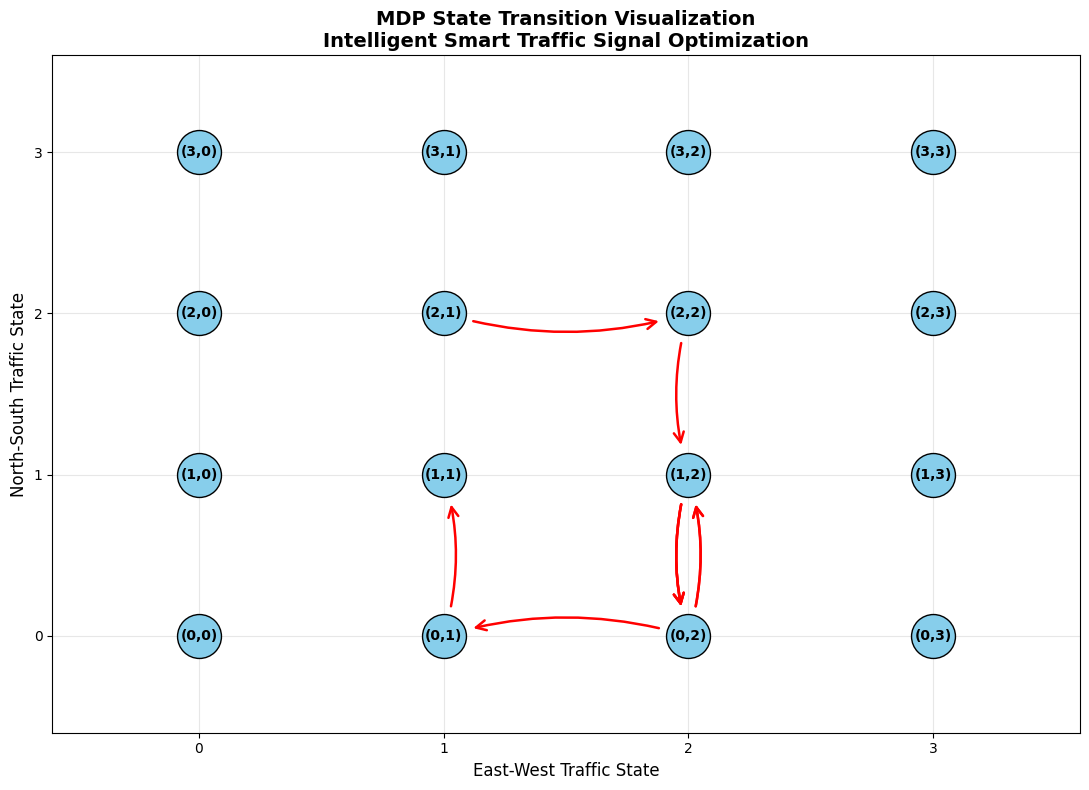

MDP State Transition Graph generated successfully!


In [28]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# Check whether Step 4 results exist
if "transition_df" not in globals():
    raise NameError("Please run Step 4 first to generate transition_df.")

fig, ax = plt.subplots(figsize=(11, 8))

# Plot state positions: x = EW state, y = NS state
for ns in range(4):
    for ew in range(4):
        ax.scatter(ew, ns, s=1000, color="skyblue",
                   edgecolors="black", zorder=3)
        ax.text(ew, ns, f"({ns},{ew})",
                ha="center", va="center",
                fontsize=10, fontweight="bold", zorder=4)

# Draw transitions observed in Step 4
for _, row in transition_df.iterrows():

    current = eval(row["Current State"])
    next_state = eval(row["Next State"])

    start = (current[1], current[0])
    end = (next_state[1], next_state[0])

    # Draw arrow
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="->",
        mutation_scale=18,
        color="red",
        linewidth=1.8,
        connectionstyle="arc3,rad=0.15",
        shrinkA=22,
        shrinkB=22,
        zorder=2
    )

    ax.add_patch(arrow)

ax.set_xlim(-0.6, 3.6)
ax.set_ylim(-0.6, 3.6)

ax.set_xticks(range(4))
ax.set_yticks(range(4))

ax.set_xlabel("East-West Traffic State", fontsize=12)
ax.set_ylabel("North-South Traffic State", fontsize=12)

ax.set_title(
    "MDP State Transition Visualization\n"
    "Intelligent Smart Traffic Signal Optimization",
    fontsize=14,
    fontweight="bold"
)

ax.grid(alpha=0.3)
plt.tight_layout()

# Save graph
plt.savefig("MDP_State_Transition_Graph.png",
            dpi=300, bbox_inches="tight")

plt.show()

print("MDP State Transition Graph generated successfully!")

In [29]:
from IPython.display import display, Markdown
import pandas as pd

# MDP formulation
mdp_data = {
    "Component": [
        "State Space (S)",
        "Action Space (A)",
        "Transition (P)",
        "Reward Function (R)",
        "Discount Factor (γ)"
    ],
    "Description": [
        "Discretized North-South and East-West traffic queues.",
        "Action 0: North-South Green; Action 1: East-West Green.",
        "Vehicle arrivals and traffic service determine the next state.",
        "R = -(NS Queue + EW Queue).",
        "γ = 0.95, giving importance to future rewards."
    ]
}

mdp_table = pd.DataFrame(mdp_data)

display(mdp_table)

# Save MDP formulation
mdp_table.to_csv("Final_MDP_Formulation.csv", index=False)

# Mathematical explanation
mdp_text = """
# Final MDP Formulation
## Intelligent Smart Traffic Signal Optimization Using Reinforcement Learning

### 1. State Space (S)
The state represents the traffic queue lengths in two directions.

S = (NS State, EW State)

Each queue is divided into four levels:
- State 0: 0–2 vehicles
- State 1: 3–5 vehicles
- State 2: 6–8 vehicles
- State 3: 9 or more vehicles

Total possible states = 4 × 4 = 16.

### 2. Action Space (A)
The agent can select one of two actions:
- A0: Give green signal to North-South traffic.
- A1: Give green signal to East-West traffic.

### 3. Transition Function (P)
The environment changes according to the selected signal action,
random vehicle arrivals, and the traffic service rate.

P(s'|s,a) represents the probability of reaching the next state
s' from the current state s after action a.

The Q-Learning implementation is model-free. It learns from
environment interactions and does not require an explicitly
calculated transition probability matrix.

### 4. Reward Function (R)

R = -(Q_NS + Q_EW)

The reward is negative because the objective is to minimize
the total number of waiting vehicles.

Lower queue lengths produce a higher (less negative) reward.

### 5. Discount Factor (Gamma)

γ = 0.95

This determines how much importance the agent gives to future rewards.

### 6. Q-Learning Update Equation

Q(s,a) = Q(s,a) + α [r + γ max Q(s',a') - Q(s,a)]

Where:
- α = 0.1 (Learning rate)
- γ = 0.95 (Discount factor)
- r = Immediate reward
- s = Current state
- a = Selected action
- s' = Next state

### 7. Objective

The main objective is to learn a traffic signal control policy
that minimizes vehicle waiting queues and improves traffic flow.
"""

with open("Final_MDP_Explanation.txt", "w") as file:
    file.write(mdp_text)

display(Markdown(mdp_text))

print("Final MDP formulation and explanation saved successfully!")

,Component,Description
0,State Space (S),Discretized North-South and East-West traffic ...
1,Action Space (A),Action 0: North-South Green; Action 1: East-We...
2,Transition (P),Vehicle arrivals and traffic service determine...
3,Reward Function (R),R = -(NS Queue + EW Queue).
4,Discount Factor (γ),"γ = 0.95, giving importance to future rewards."



# Final MDP Formulation
## Intelligent Smart Traffic Signal Optimization Using Reinforcement Learning

### 1. State Space (S)
The state represents the traffic queue lengths in two directions.

S = (NS State, EW State)

Each queue is divided into four levels:
- State 0: 0–2 vehicles
- State 1: 3–5 vehicles
- State 2: 6–8 vehicles
- State 3: 9 or more vehicles

Total possible states = 4 × 4 = 16.

### 2. Action Space (A)
The agent can select one of two actions:
- A0: Give green signal to North-South traffic.
- A1: Give green signal to East-West traffic.

### 3. Transition Function (P)
The environment changes according to the selected signal action,
random vehicle arrivals, and the traffic service rate.

P(s'|s,a) represents the probability of reaching the next state
s' from the current state s after action a.

The Q-Learning implementation is model-free. It learns from
environment interactions and does not require an explicitly
calculated transition probability matrix.

### 4. Reward Function (R)

R = -(Q_NS + Q_EW)

The reward is negative because the objective is to minimize
the total number of waiting vehicles.

Lower queue lengths produce a higher (less negative) reward.

### 5. Discount Factor (Gamma)

γ = 0.95

This determines how much importance the agent gives to future rewards.

### 6. Q-Learning Update Equation

Q(s,a) = Q(s,a) + α [r + γ max Q(s',a') - Q(s,a)]

Where:
- α = 0.1 (Learning rate)
- γ = 0.95 (Discount factor)
- r = Immediate reward
- s = Current state
- a = Selected action
- s' = Next state

### 7. Objective

The main objective is to learn a traffic signal control policy
that minimizes vehicle waiting queues and improves traffic flow.


Final MDP formulation and explanation saved successfully!


In [30]:
import os
import zipfile

# Task 3 output files
files_to_package = [
    "MDP_Architecture.png",
    "MDP_State_Transitions.csv",
    "MDP_State_Transition_Graph.png",
    "Final_MDP_Formulation.csv",
    "Final_MDP_Explanation.txt"
]

zip_name = "TASK3_MDP_FINAL_MATERIALS.zip"

available_files = []
missing_files = []

for file in files_to_package:
    if os.path.exists(file):
        available_files.append(file)
    else:
        missing_files.append(file)

# Create ZIP
with zipfile.ZipFile(zip_name, "w") as zipf:
    for file in available_files:
        zipf.write(file)

print("TASK 3 FILES PACKAGED SUCCESSFULLY!")
print("\nIncluded files:")

for file in available_files:
    print("✓", file)

if missing_files:
    print("\nFiles not found:")
    for file in missing_files:
        print("✗", file)

print("\nZIP created:", zip_name)

from google.colab import files
files.download(zip_name)

TASK 3 FILES PACKAGED SUCCESSFULLY!

Included files:
✓ MDP_Architecture.png
✓ MDP_State_Transitions.csv
✓ MDP_State_Transition_Graph.png
✓ Final_MDP_Formulation.csv
✓ Final_MDP_Explanation.txt

ZIP created: TASK3_MDP_FINAL_MATERIALS.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import os
import zipfile

# Task 3 output files
files_to_package = [
    "MDP_Architecture.png",
    "MDP_State_Transitions.csv",
    "MDP_State_Transition_Graph.png",
    "Final_MDP_Formulation.csv",
    "Final_MDP_Explanation.txt"
]

zip_name = "TASK3_MDP_FINAL_MATERIALS.zip"

available_files = []
missing_files = []

for file in files_to_package:
    if os.path.exists(file):
        available_files.append(file)
    else:
        missing_files.append(file)

# Create ZIP
with zipfile.ZipFile(zip_name, "w") as zipf:
    for file in available_files:
        zipf.write(file)

print("TASK 3 FILES PACKAGED SUCCESSFULLY!")
print("\nIncluded files:")

for file in available_files:
    print("✓", file)

if missing_files:
    print("\nFiles not found:")
    for file in missing_files:
        print("✗", file)

print("\nZIP created:", zip_name)

from google.colab import files
files.download(zip_name)

TASK 3 FILES PACKAGED SUCCESSFULLY!

Included files:
✓ MDP_Architecture.png
✓ MDP_State_Transitions.csv
✓ MDP_State_Transition_Graph.png
✓ Final_MDP_Formulation.csv
✓ Final_MDP_Explanation.txt

ZIP created: TASK3_MDP_FINAL_MATERIALS.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>